# Matched-task physical-wire-0 Lindblad rewrite

The matched task is **n=4, r=211, local Z0 and all 15,756 complete trials**, with $t=1$, $J=0.6$, $h_x=0.35$, rates 0.8/0.5/0.5/0.5 and +i/+/+/+ input. Every trial includes 1,481 source resets and eight final system/environment readouts. The repeated trial population and hardware schedule are unexecuted.

This notebook reads the separate port bundle and checks its saved identities, small matrices and accounting. It does not regenerate historical circuits, synthesize rotations, propagate a full candidate density or start a physical search. It distinguishes recovered words, a frozen structural recipe, a verified complete candidate and completed native profile reports. Missing or failed stages remain explicit.

The completed n4 baseline is preserved, including its two `infeasible_declared_controller_model` reports. This one predeclared rewrite keeps the same requested accuracy, trial population, physical assumptions and factory interface. A passing controller calculation is only a necessary condition for a native physical point.


In [1]:
from pathlib import Path
from fractions import Fraction
from collections import Counter
import hashlib, importlib.metadata, json, math, os, platform, re, stat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

BYTE_CAP = 32*1024**2
root = Path.cwd()
if (root / "word-catalog.json").is_file():
    asset_dir = root
else:
    if root.name == "notebooks" and (root.parent / "PLAN.md").is_file():
        root = root.parent
    asset_dir = root / "assets/generated/simulation/lindblad-port"

def payload_path(name):
    relative = Path(name)
    assert not relative.is_absolute() and ".." not in relative.parts, name
    path = asset_dir / relative
    assert not path.is_symlink(), name
    for parent in path.parents:
        if parent == asset_dir.parent:
            break
        assert not parent.is_symlink(), name
    return path

def file_bytes(name, maximum=BYTE_CAP):
    path = payload_path(name)
    assert path.is_file() and path.stat().st_size <= maximum, name
    fd = os.open(path, os.O_RDONLY | getattr(os, "O_NOFOLLOW", 0))
    with os.fdopen(fd, "rb") as handle:
        before = os.fstat(handle.fileno())
        assert stat.S_ISREG(before.st_mode) and before.st_size <= maximum, name
        data = handle.read(maximum+1)
        after = os.fstat(handle.fileno())
        assert len(data) <= maximum and before.st_size == after.st_size == len(data), name
    assert not path.is_symlink() and path.stat().st_size == len(data), name
    return data

def load_json(name, maximum=BYTE_CAP):
    value = json.loads(file_bytes(name, maximum))
    assert isinstance(value, dict), name
    return value

def canonical_bytes(value):
    return (json.dumps(value, sort_keys=True, separators=(",", ":"), allow_nan=False)+"\n").encode()

def table(rows):
    frame = rows if isinstance(rows, pd.DataFrame) else pd.DataFrame(rows)
    display(frame.style.hide(axis="index").format(lambda x: f"{x:.9g}" if isinstance(x,(float,np.floating)) else str(x), na_rep="—"))

def density(record):
    value = np.array(record["real"], dtype=float) + 1j*np.array(record["imag"], dtype=float)
    assert value.shape == (16,16) and np.isfinite(value).all()
    return value

def trace_norm(value):
    return float(np.linalg.svd(value, compute_uv=False).sum())

source_ready = all((asset_dir/name).is_file() for name in ("word-catalog.json", "recipe.json", "source-proof.json", "manifest.json"))
assert source_ready, "Download the complete frozen lindblad-port bundle beside this notebook or run from the repository."
EXPECTED_MANIFEST_SHA256 = "7328a265464a9bbd25875c565d62ee4921f59d42af239deedec4951dbd17a83b"
EXPECTED_RESULTS_SHA256 = "58ae0a0e7f5c2eeaf4ff3aae6df36fbd063a3e49b7c06362e6aa1c6ade678732"
assert hashlib.sha256(file_bytes("manifest.json")).hexdigest() == EXPECTED_MANIFEST_SHA256
assert hashlib.sha256(file_bytes("results.json")).hexdigest() == EXPECTED_RESULTS_SHA256
catalog = recipe = proof = manifest = results = candidate = None
if source_ready:
    manifest = load_json("manifest.json")
    for name, expected in manifest["artifacts_sha256"].items():
        assert re.fullmatch(r"[0-9a-f]{64}", expected), name
        assert hashlib.sha256(file_bytes(name)).hexdigest() == expected, name
    catalog = load_json("word-catalog.json", 4*1024**2)
    recipe = load_json("recipe.json", 8*1024**2)
    proof = load_json("source-proof.json")
    assert proof["status"] == "completed_source_only_recipe"
    assert proof["candidate_materialized"] is False and proof["candidate_full_density_executed"] is False
    assert proof["new_synthesis_calls"] == proof["native_physical_queries"] == 0
    for name,expected in proof["artifact_sha256"].items():
        assert manifest["artifacts_sha256"][name] == expected, name
        assert hashlib.sha256(file_bytes(name)).hexdigest() == expected, name
    assert proof["source_sha256"] == manifest["source_sha256"]
    for name,expected in manifest["source_sha256"].items():
        assert hashlib.sha256(file_bytes(name)).hexdigest() == expected, name
    assert proof["baseline_artifacts_sha256"] == catalog["source_artifacts"] == recipe["source_artifacts"]
    assert proof["baseline_artifacts_sha256"]["manifest.json"] == "5e78c5deac53d8106539ae75c5edbab4027ead7439c2bd4a2e491ec37834296f"
    assert proof["baseline_artifacts_sha256"]["results.json"] == "a7451fd56010cbcf6d0591e55c30d154c6e02fed4ce850a02a0a9c604e985002"
    for name,expected in recipe["source_sha256"].items():
        assert manifest["source_sha256"][name] == expected, name
    assert proof["catalog_recovery_sha256"] == manifest["catalog_recovery_sha256"] == catalog["recovery_sha256"]
    assert proof["recipe_sha256"] == manifest["recipe_sha256"]
    runtime = manifest["runtime"]
    assert runtime == proof["runtime"]
    assert platform.python_version() == runtime["python"] == "3.12.14"
    for name, expected in runtime["packages"].items():
        assert importlib.metadata.version(name) == expected, name
    if (asset_dir/"results.json").is_file():
        results = load_json("results.json")
        candidate = results.get("candidate")
        assert results["status"] == "completed_candidate_and_bounded_native_profiles"
        assert candidate is not None and len(results["physical_profiles"]) == 2
    print("Saved bundle hashes and locked runtime verified.")
    print("Saved run status:", results.get("status") if results else "source artifacts only; complete candidate pending")
else:
    print("Pending: the gated source-stage bundle has not been exported. No candidate or feasibility result is displayed.")


Saved bundle hashes and locked runtime verified.
Saved run status: completed_candidate_and_bounded_native_profiles


## Recover the actual phased words

All 5,908 routed rotations must match the eight words recovered from the complete saved Clifford+T stream. The individual QASMs restore each recorded binary64 phase with `gphase`; a full operator comparison includes that phase. An operator comparison only up to phase does not establish this recovery. The new bundle records the token sequence, counts, phase in hexadecimal, QASM hash, matrix and saved target error for every word. No new synthesis is required after those checks pass.

The existing synthesis policy and pinned Qiskit 2.6.2/QDK 1.34.0 environment remain the baseline. Qiskit’s recorded Cargo.lock identifies the native `rsgridsynth` 0.2.2 dependency; the installed wheel exposes no direct native-crate version certificate. The recovered word equality checks are numerical checks, not an interval or formal certificate {cite:p}`sim_qiskit_262,resource_rsgridsynth_022,resource_ross_selinger_2014,resource_qdk_134`.


word,rotation,primitives,occurrences,T,recorded guarded error
word-00,rz,462,1266,182,2.89883074e-09
word-01,rx,233,1688,89,9.46793936e-10
word-02,ry,225,422,85,1.46175712e-09
word-03,ry,225,422,85,1.46175712e-09
word-04,ry,230,844,90,9.94184012e-10
word-05,ry,230,844,90,9.94184012e-10
word-06,ry,244,211,90,1.39658731e-09
word-07,ry,244,211,90,1.39658731e-09


Maximum full phased-operator replay residual: 0.0
Phase-omitted residual range: 1.0823922002923847 2.7740796906442724


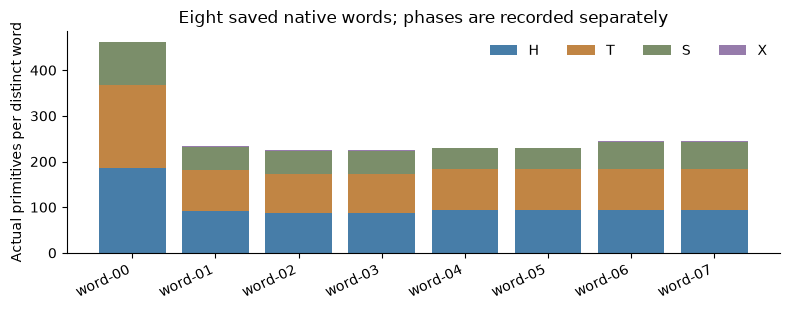

In [2]:
if source_ready:
    words = catalog["words"]
    assert catalog["word_count"] == len(words) == 8
    assert sum(word["operations"] for word in words) == 2093
    assert sum(word["occurrences"] for word in words) == 5908
    assert catalog["new_synthesis_calls"] == 0
    catalog_payload = dict(catalog)
    catalog_digest = catalog_payload.pop("recovery_sha256")
    assert hashlib.sha256(canonical_bytes(catalog_payload)).hexdigest() == catalog_digest
    primitive_matrices = {
        "h": np.array([[1,1],[1,-1]], complex)/math.sqrt(2),
        "t": np.diag([1,np.exp(1j*math.pi/4)]),
        "tdg": np.diag([1,np.exp(-1j*math.pi/4)]),
        "s": np.diag([1,1j]), "sdg": np.diag([1,-1j]),
        "x": np.array([[0,1],[1,0]], complex),
        "y": np.array([[0,-1j],[1j,0]], complex), "z": np.diag([1,-1])}
    operator_residuals = []
    phase_omission_residuals = []
    for word in words:
        phase = float.fromhex(word["global_phase_binary64_hex"])
        assert word["global_phase_radians"] == phase
        assert word["operations"] == len(word["tokens"]) == sum(word["gate_counts"].values())
        assert hashlib.sha256(canonical_bytes(word["tokens"])).hexdigest() == word["sequence_sha256"]
        raw = file_bytes(word["qasm_path"], 32*1024)
        assert hashlib.sha256(raw).hexdigest() == word["qasm_sha256"]
        lines = raw.decode().splitlines()
        assert lines[:3] == ["OPENQASM 3.0;", 'include "stdgates.inc";', "qubit[1] q;"]
        assert lines[3] == f"gphase({phase!r});"
        assert lines[4:] == [f'{token["name"]} q[0];' for token in word["tokens"]]
        bare = np.eye(2, dtype=complex)
        counts = Counter()
        for token in word["tokens"]:
            assert token["qubits"] == [0] and token["clbits"] == token["params_hex"] == []
            bare = primitive_matrices[token["name"]] @ bare
            counts[token["name"]] += 1
        assert dict(counts) == word["gate_counts"]
        actual = np.exp(1j*phase)*bare
        recorded = np.array(word["matrix"]["real"]) + 1j*np.array(word["matrix"]["imag"])
        assert recorded.shape == (2,2) and np.isfinite(recorded).all()
        residual = float(np.linalg.norm(actual-recorded, "fro"))
        operator_residuals.append(residual)
        assert residual <= 1e-12
        angle = float.fromhex(word["angle_hex"])
        c,s = math.cos(angle/2), math.sin(angle/2)
        axis = word["rotation_gate"]
        assert axis in {"rx","ry","rz"}
        target = np.array([[c,-1j*s],[-1j*s,c]]) if axis == "rx" else np.array([[c,-s],[s,c]]) if axis == "ry" else np.diag([np.exp(-1j*angle/2),np.exp(1j*angle/2)])
        guarded_error = float(np.linalg.norm(actual-target, "fro")) + 1e-12
        assert abs(guarded_error-word["recorded_guarded_frobenius_error"]) <= 1e-12
        phase_omission_residuals.append(float(np.linalg.norm(bare-recorded,"fro")))
    table([{"word":w["word_id"], "rotation":w["rotation_gate"], "primitives":w["operations"], "occurrences":w["occurrences"], "T":w["gate_counts"].get("t",0)+w["gate_counts"].get("tdg",0), "recorded guarded error":w["recorded_guarded_frobenius_error"]} for w in words])
    print("Maximum full phased-operator replay residual:", max(operator_residuals))
    print("Phase-omitted residual range:", min(phase_omission_residuals), max(phase_omission_residuals))
    fig, ax = plt.subplots(figsize=(8,3.2))
    x = np.arange(len(words))
    bottom = np.zeros(len(words))
    for gate,color in (("h","#477da8"),("t","#c18544"),("s","#7b8e6a"),("x","#967bab")):
        heights=np.array([w["gate_counts"].get(gate,0) for w in words])
        ax.bar(x, heights, bottom=bottom, label=gate.upper(), color=color)
        bottom += heights
    ax.set_xticks(x, [w["word_id"] for w in words], rotation=25, ha="right")
    ax.set_ylabel("Actual primitives per distinct word")
    ax.set_title("Eight saved native words; phases are recorded separately")
    ax.legend(ncol=4, frameon=False)
    ax.spines[["top","right"]].set_visible(False)
    fig.tight_layout(); plt.show()
else:
    print("Recovered-word table pending source-stage export.")


## Freeze one reversible port recipe

For a rotation on physical wire $w$, the recipe checks that every wire $0,\ldots,w$ has already received an explicit initialization. It then moves the data from $w$ to 0 with descending adjacent SWAPs, applies the identical bare recovered token word on 0 and reverses the path with ascending SWAPs. Each SWAP has three nearest-neighbor CNOTs, so the block adds exactly $2w$ SWAPs or $6w$ CNOTs. If the initialized-path condition fails, it keeps the original word.

The unchanged factory port reaches each data wire through reserved workspace and adjacent transport. Applying a long Clifford+T word at wire $w$ repeatedly pays that route for its T gates. Moving the data for one whole verified word amortizes the added CNOTs over those T occurrences. In the frozen macro ledger, CX costs 11 controller decisions and moving one T left by one wire removes 33, so this block changes the demand by $33w(2-N_T)$ for its actual T count $N_T$. Every T at wire 0 still pays its factory, handoff, workspace and feedback costs.

Restoration happens before the next source instruction. Every nonrotation instruction, reset, ignored readout and barrier remains in order, and the final mapping to c0…c7 remains `[6,1,2,3,7,4,0,5]`. The original complete compiled phase is carried verbatim once. Word-level phases are checked during recovery and are not added again while embedding their bare tokens.

The canonical recipe binds the saved input hashes, all rotation indices and CT ranges, initialized masks, word identities, swap paths, source code and matched-task contract before candidate execution. Structural recipe counts are distinct from actual emitted-candidate counts.


In [3]:
if source_ready:
    recipe_payload = dict(recipe)
    recipe_digest = recipe_payload.pop("recipe_sha256", proof["recipe_sha256"])
    assert hashlib.sha256(canonical_bytes(recipe_payload)).hexdigest() == recipe_digest
    assert recipe["catalog_sha256"] == catalog["recovery_sha256"]
    assert proof["recipe_sha256"] == recipe_digest
    assert recipe["global_phase_binary64_hex"] == catalog["baseline_global_phase_binary64_hex"]
    assert recipe["phase_rule"] == "bare words plus authoritative baseline global phase exactly once"
    plan = recipe["plan"]
    blocks = plan["rotation_blocks"]
    assert len(blocks) == plan["eligible_rotation_blocks"] + plan["fallback_rotation_blocks"] == 5908
    assert plan["eligible_rotation_blocks"] == 5908 and plan["fallback_rotation_blocks"] == 0
    assert plan["baseline_operations"] == 1677906 and plan["routed_operations"] == 24510
    assert plan["added_cx"] == 123864 and plan["planned_operations"] == 1801770
    assert plan["planned_operations"] == plan["baseline_operations"] + plan["added_cx"]
    assert plan["final_measurement_wires"] == [6,1,2,3,7,4,0,5]
    assert plan["final_measurement_clbits"] == list(range(8))
    assert plan["planned_t_wire_counts"] == [642284,0,0,0,0,0,0,0]
    previous_ct = previous_routed = -1
    for block in blocks:
        assert block["ct_start"] > previous_ct and block["routed_index"] > previous_routed
        previous_ct, previous_routed = block["ct_start"], block["routed_index"]
        wire = block["original_wire"]
        assert 0 <= wire < 8 and block["eligible"] is True
        assert block["initialized_mask"] & ((1 << (wire+1))-1) == (1 << (wire+1))-1
        forward = [[i,i+1] for i in range(wire-1,-1,-1)]
        assert block["forward_swap_edges"] == forward and block["reverse_swap_edges"] == forward[::-1]
        assert block["target_wire"] == 0 and block["added_cx"] == 6*wire
    assert sum(block["added_cx"] for block in blocks) == plan["added_cx"]
    assert recipe["candidate_materialized"] is False and recipe["full_density_executed"] is False
    assert recipe["native_physical_queries"] == recipe["new_synthesis_calls"] == 0
    print("Frozen recipe digest:", recipe_digest)
    print("Catalog recovery digest:", catalog["recovery_sha256"])
    table([{"structural source-only quantity":"rotation occurrences", "planned value":len(blocks)},
           {"structural source-only quantity":"eligible / fallback paths", "planned value":f'{plan["eligible_rotation_blocks"]} / {plan["fallback_rotation_blocks"]}'},
           {"structural source-only quantity":"added nearest-neighbor CX", "planned value":plan["added_cx"]},
           {"structural source-only quantity":"candidate instructions", "planned value":plan["planned_operations"]}])
else:
    table([{"structural source-only quantity":"rotation occurrences", "planned value":5908},
           {"structural source-only quantity":"eligible / unsafe paths", "planned value":"5908 / 0"},
           {"structural source-only quantity":"added nearest-neighbor CX", "planned value":123864},
           {"structural source-only quantity":"candidate instructions", "planned value":1801770}])
print("These source-only planned counts are not candidate execution or physical feasibility.")


Frozen recipe digest: 2e46759e17a71b98b7547e35b97b42976f840b350fbcceab6fd33eaec941a1b5
Catalog recovery digest: f8da75f64523c8e4f7999d356aae968f46c2da389f01e9bfcedcd204c157a767


structural source-only quantity,planned value
rotation occurrences,5908
eligible / fallback paths,5908 / 0
added nearest-neighbor CX,123864
candidate instructions,1801770


These source-only planned counts are not candidate execution or physical feasibility.


## Verify the complete correlated candidate

The authorized complete candidate runs only after word and recipe review. Its checker retains the full eight-wire $256\times256$ density operator, including reset and ignored-readout channels, then captures the four-system $16\times16$ state and all 16 joint probabilities. It compares the new candidate with the saved source, baseline CT and independently assembled GKSL reference. Those historical calculations are not rerun here.

The predeclared state/trace guard is $10^{-8}$ and full candidate-to-baseline density agreement guard is $10^{-10}$. The checker preserves raw trace and divides the captured reduced state by that trace once. This numerical normalization introduces no acceptance condition or quantum postselection. Agreement of the local Z0 score alone would not establish preservation of the interacting correlated state.


saved instrument,Z0,raw trace drift,normalized trace residual,Hermiticity trace norm,minimum eigenvalue
candidate,0.791051346,1.72785009e-10,2.03752007e-15,1.66092524e-14,0.000108585747
saved baseline CT,0.791051346,1.72785786e-10,3.11544789e-16,1.41321929e-14,0.000108585747
saved source,0.791051439,2.67563749e-14,2.22058119e-16,8.51128404e-15,0.000108585464


comparison,recomputed value
candidate vs saved ct normalized trace norm,1.42742843e-14
candidate vs saved ct raw trace norm,1.4461857e-14
candidate vs saved ct joint maximum absolute,1.49880108e-15
candidate vs saved ct raw trace absolute,7.77156117e-16
candidate vs saved source normalized trace norm,1.9435236e-06
candidate vs saved source raw trace norm,1.94352917e-06
candidate vs saved source joint maximum absolute,1.60544437e-07
candidate vs saved source Z0 absolute,9.29540128e-08
candidate vs saved GKSL normalized trace norm,5.69201318e-06
candidate vs saved GKSL raw trace norm,5.69200802e-06


gate,baseline instructions,actual port instructions,calculated population occurrences
barrier,2978,2978,46921368
cx,14130,137994,2174233464
h,661278,661278,10419096168
measure,8,8,126048
reset,1481,1481,23334636
s,349839,349839,5512063284
t,642284,642284,10119826704
x,5908,5908,93086448


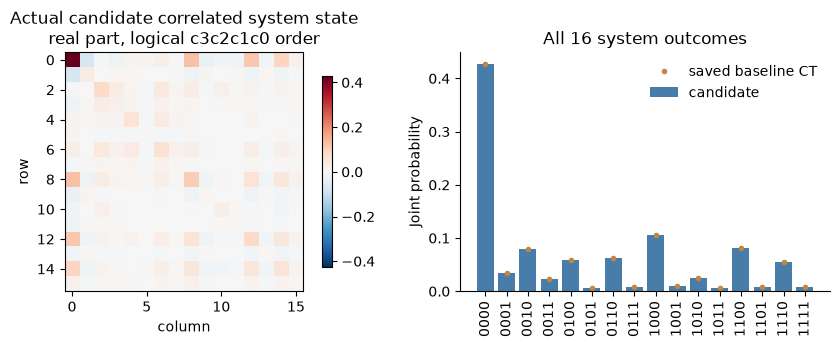

In [4]:
if candidate is None:
    print("Complete candidate density and event/count verification pending; no full-state success is claimed.")
else:
    assert candidate["status"] == "verified_complete_port_candidate"
    assert candidate["case_id"] == "lindblad-n4-r211-Z0"
    assert candidate["candidate_full_density_executed"] is True
    assert candidate["candidate_density_execution_count"] == 1
    assert candidate["historical_density_execution_count"] == candidate["new_synthesis_calls"] == 0
    assert candidate["recipe_sha256"] == recipe_digest
    assert candidate["catalog_sha256"] == catalog["recovery_sha256"]
    assert candidate["source_artifacts"] == proof["baseline_artifacts_sha256"]
    assert candidate["materialization_limits"] == {"max_qubits":8,"source_operations":20000,"reference_operations":100000,"candidate_operations":2000000}
    actual = candidate["candidate_report"]
    assert actual["recipe_sha256"] == recipe_digest
    assert actual["catalog_sha256"] == catalog["recovery_sha256"]
    assert actual["source_artifacts"] == proof["baseline_artifacts_sha256"]
    assert actual["source_sha256"] == recipe["source_sha256"]
    assert results["candidate_qasm_sha256"] == manifest["artifacts_sha256"]["candidate-trial.qasm"]
    assert results["candidate_global_phase_binary64_hex"] == recipe["global_phase_binary64_hex"]
    qasm_raw = file_bytes("candidate-trial.qasm")
    phase = float.fromhex(recipe["global_phase_binary64_hex"])
    assert qasm_raw.split(b"\n",5)[:5] == [b"OPENQASM 3.0;",b'include "stdgates.inc";',b"bit[8] c;",b"qubit[8] q;",f"gphase({phase!r});".encode()]
    assert qasm_raw.count(b"gphase(") == 1
    del qasm_raw
    assert actual["actual_operations"] == recipe["plan"]["planned_operations"] == 1801770
    assert actual["gate_counts"] == recipe["plan"]["planned_gate_counts"]
    assert actual["added_cx"] == 123864
    assert actual["t_wire_counts"] == [642284,0,0,0,0,0,0,0]
    assert actual["event_sha256"] == recipe["plan"]["event_sha256"]
    assert actual["final_measurement_wires"] == [6,1,2,3,7,4,0,5]
    assert actual["final_measurement_clbits"] == list(range(8))
    assert actual["global_phase_binary64_hex"] == recipe["global_phase_binary64_hex"]
    checks = {
        "candidate": candidate["candidate_instrument_check"],
        "saved baseline CT": candidate["saved_clifford_t_instrument_check"],
        "saved source": candidate["saved_source_instrument_check"]}
    matrices = {}; laws = {}; raw_traces = {}; invariant_rows = []
    for name, check in checks.items():
        rho = density(check["reduced_before_output"])
        law = np.array(check["joint_probabilities"],dtype=float)
        trace = check["unnormalized_trace_before_output"]
        assert isinstance(trace,float) and math.isfinite(trace) and abs(trace-1) <= 1e-8
        assert check["acceptance_probability"] == check["normalization_divisor"] == trace
        assert check["normalization_is_postselection"] is False
        assert check["outcome_clbits"] == [0,1,2,3] and check["score_values"] == [1 if i%2 == 0 else -1 for i in range(16)]
        assert law.shape == (16,) and np.isfinite(law).all()
        trace_residual = abs(complex(np.trace(rho))-1)
        hermiticity = trace_norm(rho-rho.conj().T)
        minimum = float(np.linalg.eigvalsh((rho+rho.conj().T)/2).min())
        assert trace_residual <= 1e-10 and hermiticity <= 1e-8 and minimum >= -1e-8
        assert abs(float(sum(law))-1) <= 1e-10 and float(law.min()) >= -1e-8
        assert float(np.max(np.abs(np.diag(rho).real-law))) <= 1e-10
        assert abs(float(np.dot(check["score_values"],law))-check["mean"]) <= 1e-10
        matrices[name], laws[name], raw_traces[name] = rho, law, trace
        invariant_rows.append({"saved instrument":name,"Z0":check["mean"],"raw trace drift":abs(trace-1),"normalized trace residual":trace_residual,"Hermiticity trace norm":hermiticity,"minimum eigenvalue":minimum})
    a,c,s = matrices["candidate"], matrices["saved baseline CT"], matrices["saved source"]
    at,ct,st = raw_traces["candidate"], raw_traces["saved baseline CT"], raw_traces["saved source"]
    ap,cp,sp = laws["candidate"], laws["saved baseline CT"], laws["saved source"]
    recomputed = {
        "candidate_vs_saved_ct_normalized_trace_norm":trace_norm(a-c),
        "candidate_vs_saved_ct_raw_trace_norm":trace_norm(a*at-c*ct),
        "candidate_vs_saved_ct_joint_maximum_absolute":float(np.max(abs(ap-cp))),
        "candidate_vs_saved_ct_raw_trace_absolute":abs(at-ct),
        "candidate_vs_saved_source_normalized_trace_norm":trace_norm(a-s),
        "candidate_vs_saved_source_raw_trace_norm":trace_norm(a*at-s*st),
        "candidate_vs_saved_source_joint_maximum_absolute":float(np.max(abs(ap-sp))),
        "candidate_vs_saved_source_Z0_absolute":abs(checks["candidate"]["mean"]-checks["saved source"]["mean"])}
    for key,value in recomputed.items():
        assert abs(value-candidate["saved_baseline_comparisons"][key]) <= 1e-12, key
    assert recomputed["candidate_vs_saved_ct_normalized_trace_norm"] <= 1e-10
    assert recomputed["candidate_vs_saved_ct_joint_maximum_absolute"] <= 1e-10
    assert recomputed["candidate_vs_saved_ct_raw_trace_norm"] <= 1e-10
    assert recomputed["candidate_vs_saved_ct_raw_trace_absolute"] <= 1e-8
    exact = density(candidate["saved_independent_reference"]["exact_GKSL_system_density"])
    recomputed["candidate_vs_saved_GKSL_normalized_trace_norm"] = trace_norm(a-exact)
    recomputed["candidate_vs_saved_GKSL_raw_trace_norm"] = trace_norm(a*at-exact)
    recomputed["candidate_vs_saved_GKSL_joint_maximum_absolute"] = float(np.max(abs(ap-np.diag(exact).real)))
    recomputed["candidate_vs_saved_GKSL_Z0_absolute"] = abs(checks["candidate"]["mean"]-candidate["saved_independent_reference"]["exact_GKSL_Z0"])
    for key,value in recomputed.items():
        assert abs(value-candidate["saved_baseline_comparisons"][key]) <= 1e-12, key
    assert set(recomputed) == set(candidate["saved_baseline_comparisons"])
    gksl_distance = recomputed["candidate_vs_saved_GKSL_normalized_trace_norm"]
    table(invariant_rows)
    table([{"comparison":key.replace("candidate_vs_", "candidate vs ").replace("_", " "),"recomputed value":value} for key,value in recomputed.items()]+[{"comparison":"candidate vs saved GKSL normalized trace norm","recomputed value":gksl_distance}])
    table([{"gate":name,"baseline instructions":recipe["plan"]["baseline_gate_counts"].get(name,0),"actual port instructions":value,"calculated population occurrences":value*15756} for name,value in actual["gate_counts"].items()])
    fig, axes = plt.subplots(1,2,figsize=(9,3.5))
    image=axes[0].imshow(a.real,cmap="RdBu_r",vmin=-float(np.max(np.abs(a.real))),vmax=float(np.max(np.abs(a.real))))
    axes[0].set_title("Actual candidate correlated system state\nreal part, logical c3c2c1c0 order")
    axes[0].set_xlabel("column"); axes[0].set_ylabel("row"); fig.colorbar(image,ax=axes[0],shrink=.8)
    x=np.arange(16)
    axes[1].bar(x,ap,color="#477da8",label="candidate")
    axes[1].plot(x,cp,"o",ms=3,color="#c18544",label="saved baseline CT")
    axes[1].set_xticks(x,[format(i,"04b") for i in x],rotation=90)
    axes[1].set_ylabel("Joint probability"); axes[1].set_title("All 16 system outcomes")
    axes[1].legend(frameon=False); axes[1].spines[["top","right"]].set_visible(False)
    fig.tight_layout(); plt.show()


## Keep the accuracy and confidence contract fixed

The absolute-error target remains 0.05: 0.01 splitting, 0.01 realization and 0.03 statistics. The case uses exact statistical failure $1/600$ and separate physical/readiness allowances of $1/1200$ each. The whole-trial synthesis request is $5\times10^{-5}$ with separate $10^{-7}$ representation and $10^{-7}$ SDK/control/routing premises. The same 15,756 trials remain in every population ledger.

These deterministic bias terms are not multiplied by the trial population. Numerical density agreement does not establish the conditional norm premises. The unchanged surface-code model retains the eight-wire line, 31 patches, 23 workspace startups per trial, one just-in-time factory, the nonzero T_q0 transport/handoff/workspace/feedback costs, both $p=10^{-3}$/$10^{-4}$ profiles and controller rate $10^{-15}$ per decision.


In [5]:
if source_ready:
    contract = recipe["matched_contract"]
    error_contract = contract["error_contract"]
    workload = contract["complete_workload"]
    assert contract["task"] == {"n_system":4,"time":1.0,"J":0.6,"hx":0.35,"rate0":0.8,"other_rate":0.5}
    assert contract["selected_steps"] == 211 and contract["input_states"] == ["+i","+","+","+"]
    assert workload["complete_trials"] == workload["complete_attempts"] == 15756
    assert workload["postselection"] == "none" and workload["whole_workload_executed"] is False
    assert workload["workspace_startup_initializations_per_trial"] == 23
    assert workload["reserved_logical_patches"] == 31
    assert workload["workspace_startup_initializations_all_trials"] == 23*15756
    assert workload["logical_startup_initializations_all_trials"] == 31*15756
    assert workload["deterministic_bias_multiplied_by_trials"] is False
    for key,expected in (("statistical_failure_exact",Fraction(1,600)),("physical_failure_exact",Fraction(1,1200)),("factory_availability_failure_exact",Fraction(1,1200))):
        value=workload[key]
        assert Fraction(value["numerator"],value["denominator"]) == expected
    for key,expected in (("splitting_bias_allowance",.01),("realization_bias_allowance",.01),("statistical_absolute_error",.03),("target_absolute_error",.05),("requested_synthesis_allowance",5e-5),("representation_norm_reserve_scenario",1e-7),("SDK_control_routing_norm_reserve_scenario",1e-7)):
        assert error_contract[key] == expected
    assert error_contract["reserve_is_inferred_from_density_agreement"] is False
    assert error_contract["full_representation_certificate"] is False
    assert error_contract["formal_synthesis_certificate"] is False
    assert error_contract["hardware_confidence_certificate"] is False
    if candidate is not None:
        assert candidate["error_contract"] == error_contract
        count_fields = {"primitive_counts_per_complete_trial", "primitive_counts_all_trials"}
        assert {k:v for k,v in candidate["complete_workload"].items() if k not in count_fields} == {k:v for k,v in workload.items() if k not in count_fields}
        actual_primitives = {k:v for k,v in candidate["candidate_report"]["gate_counts"].items() if k != "barrier"}
        assert candidate["complete_workload"]["primitive_counts_per_complete_trial"] == actual_primitives
        assert candidate["complete_workload"]["primitive_counts_all_trials"] == {k:v*15756 for k,v in actual_primitives.items()}
        assert gksl_distance <= error_contract["splitting_bias_upper"]+error_contract["realization_Z0_bias_upper_proposal"]+1e-10
        assert recomputed["candidate_vs_saved_source_normalized_trace_norm"] <= error_contract["realization_Z0_bias_upper_proposal"]+1e-10
    hardware = contract["hardware"]
    assert hardware["bidirectional_line_wires"] == 8 and hardware["reserved_logical_patches"] == 31
    assert hardware["workspace_startups_per_trial"] == 23 and hardware["controller_error_per_decision"] == 1e-15
    assert hardware["physical_error_profiles"] == [1e-3,1e-4] and hardware["odd_distances"] == list(range(3,50,2))
    assert hardware["factory_retry_cap"] == 16 and hardware["whole_device_serialization"] is True
    table([{"unchanged error-contract quantity":name.replace("_"," "),"value":error_contract[name]} for name in ("splitting_bias_upper","guarded_actual_synthesis_error","realization_Z0_bias_upper_proposal","absolute_Z0_error_upper_proposal")])
else:
    table([{"quantity":"splitting absolute-error allocation", "unchanged value":0.01},
           {"quantity":"realization absolute-error allocation", "unchanged value":0.01},
           {"quantity":"statistics absolute-error allocation", "unchanged value":0.03},
           {"quantity":"case statistical / physical / readiness failure", "unchanged value":"1/600 / 1/1200 / 1/1200"},
           {"quantity":"complete trials", "unchanged value":15756},
           {"quantity":"reserved patches / workspace startups per trial", "unchanged value":"31 / 23"}])


unchanged error-contract quantity,value
splitting bias upper,0.00996533471
guarded actual synthesis error,8.76937334e-06
realization Z0 bias upper proposal,1.79387467e-05
absolute Z0 error upper proposal,0.0399832735


## Account for the actual emitted ledger before searching

The baseline controller demand is 123,409,809 decisions per trial, or 1,944,444,950,604 across the complete population. Its contribution 0.001944444950604 exceeds the unchanged physical allowance $1/1200$, so both baseline profiles remain model-infeasible. The port's controller eligibility must be calculated from its verified actual counts, T-wire positions, preparation/reset/readout events and all repetitions.

The necessary controller maximum is 52,889,904 decisions per trial. Passing that threshold does not establish a feasible code distance, factory, physical qubit count or runtime. Factory quality, full retries, readiness, exposure and all remaining physical failure components are separately required. A failed or absent physical point is reported without inventing zero qubits or zero time.


In [6]:
if candidate is None:
    print("Actual candidate controller ledger pending. Baseline statuses remain infeasible_declared_controller_model.")
else:
    actual = candidate["candidate_report"]
    baseline_t_wires = recipe["plan"]["baseline_t_wire_counts"]
    actual_t_wires = actual["t_wire_counts"]
    # Frozen CX costs 11 decisions; moving one T left one wire removes 33.
    # Only these terms change: all other gates/events and full factory retries are preserved.
    controller_per_trial = 123409809 + 11*actual["added_cx"] + 33*sum(w*(actual_t_wires[w]-baseline_t_wires[w]) for w in range(8))
    assert controller_per_trial == 50713680
    controller_population = controller_per_trial*15756
    controller_contribution = controller_population*1e-15
    magic_states = sum(actual_t_wires)*15756
    assert magic_states == 10119826704
    retry_cap = next(k for k in range(1,17) if Fraction(1,100)**k*magic_states <= Fraction(1,1200))
    assert retry_cap == 7
    readiness_bound = float(Fraction(1,100)**retry_cap*magic_states)
    table([{"quantity":"actual controller decisions per trial", "value":controller_per_trial},
           {"quantity":"necessary controller maximum per trial", "value":52889904},
           {"quantity":"calculated population controller decisions", "value":controller_population},
           {"quantity":"distance-independent controller-model contribution", "value":controller_contribution},
           {"quantity":"required magic states across calculated population", "value":magic_states},
           {"quantity":"minimal full-pipeline retry cap", "value":retry_cap},
           {"quantity":"readiness union bound", "value":readiness_bound}])
    assert controller_per_trial <= 52889904 and controller_contribution <= float(Fraction(1,1200))
    print("The verified actual controller ledger satisfies the necessary controller threshold. This is not a physical-feasibility result.")
    diagnostics = results.get("controller_eligibility", [])
    if isinstance(diagnostics, dict):
        diagnostics = list(diagnostics.values())
    if not diagnostics:
        diagnostics = [p["controller_diagnostic"] for p in results.get("physical_profiles",[]) if "controller_diagnostic" in p]
    for diagnostic in diagnostics:
        assert diagnostic["controller_decisions_per_trial"] == controller_per_trial
        assert diagnostic["controller_decisions_all_trials"] == controller_population
        assert abs(diagnostic["distance_independent_controller_model_contribution"]-controller_contribution) <= 1e-15
        assert diagnostic["factory_retry_cap"] == retry_cap
        assert abs(diagnostic["factory_readiness_failure_union_bound"]-readiness_bound) <= 1e-15
        assert diagnostic["required_magic_states_all_trials"] == magic_states
        assert diagnostic["eligibility_is_physical_feasibility"] is False
    if diagnostics:
        print("Saved controller/readiness diagnostics match the independent actual-count replay.")
    else:
        print("No separately recorded controller eligibility report is available yet.")


quantity,value
actual controller decisions per trial,50713680
necessary controller maximum per trial,52889904
calculated population controller decisions,7.99044742e+11
distance-independent controller-model contribution,0.000799044742
required magic states across calculated population,1.01198267e+10
minimal full-pipeline retry cap,7
readiness union bound,0.000101198267


The verified actual controller ledger satisfies the necessary controller threshold. This is not a physical-feasibility result.
Saved controller/readiness diagnostics match the independent actual-count replay.


## Retain both bounded native profile outcomes

The separate `estimate_verified_four` adapter requires the completed candidate/catalog/recipe/phase/density/event/count/current-source attestation and independent source approval before native calls. Its explicit two-million-operation domain does not change or impersonate the historical one-million legacy report.

Each frozen profile permits 24 top-level factory and 24 surface-code queries, at most 1,000 returned candidates per query and 24,000 per profile, and at most one Trace estimate per returned candidate. A whole profile fails on an overflow, timeout or memory violation; the search does not truncate a favorable frontier. The 180-second profile limit and 2 GiB parent/child RSS watchdog also bound native work before its first yielded candidate.


p,status,Pareto points,factory queries,surface-code queries,returned candidates within cap,Trace estimates,reason
0.001,computed_conditional_port_surface_code_model,3,24,24,257,45,
0.0001,computed_conditional_port_surface_code_model,3,24,24,252,112,


p,distance,physical qubits,calculated population runtime (s),physical failure sum,readiness bound
0.001,37,1070167,90942060.4,0.000827794427,0.000101198267
0.001,37,1581986,85699990.2,0.000826169385,0.000101198267
0.001,37,1612093,80457919.9,0.000824544343,0.000101198267
0.0001,19,267491,50695791.1,0.000800625634,0.000101198267
0.0001,19,394387,48003917.2,0.000800542186,0.000101198267
0.0001,19,402318,45312043.3,0.000800458738,0.000101198267


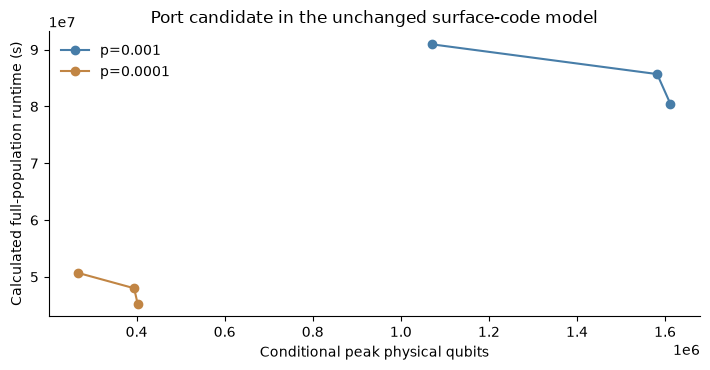

These saved points are conditional model outcomes. The repeated trial population and hardware schedule are unexecuted.


In [7]:
profiles = results.get("physical_profiles", []) if results else []
if not profiles:
    print("No completed native profile record is available. No physical feasibility or co-design gain is claimed.")
else:
    assert len(profiles) == 2
    def macro_cost(name, profile, distance, factory_ns, cap):
        dtime = distance*profile["code_cycle_time_ns"]
        init = profile["physical_initialization_time_ns"]+dtime+profile["reaction_time_ns"]
        destructive = profile["physical_measurement_time_ns"]+profile["reaction_time_ns"]
        parity = 2*init+dtime+destructive
        cnot = 3*parity+2*profile["reaction_time_ns"]
        if name == "initial_reset": return (init,0,1,1)
        if name == "reset": return (parity+2*profile["reaction_time_ns"]+dtime,1,2,5)
        if name == "measure": return (parity,1,2,3)
        if name == "cx": return (cnot,3,6,11)
        if name.startswith(("t_q","tdg_q")):
            wire=int(name.split("_q")[1]); cnots=3*(wire+1)+1
            inverse=int(name.startswith("tdg"))
            overhead=profile["physical_initialization_time_ns"]+profile["physical_measurement_time_ns"]+profile["reaction_time_ns"]
            supply=cap*(factory_ns+profile["factory_feedback_rounds_reserved"]*overhead+profile["reaction_time_ns"])
            return (supply+cnots*cnot+destructive+profile["reaction_time_ns"]+init+inverse*profile["reaction_time_ns"],3*cnots+1,6*cnots+1,11*cnots+3+inverse+cap*(profile["factory_feedback_rounds_reserved"]+1))
        assert name in {"h","s","sdg","x","y","z","trial_control"}, name
        return (profile["reaction_time_ns"],0,0,1)
    def close(actual, expected):
        assert math.isclose(actual,expected,rel_tol=1e-10,abs_tol=1e-18),(actual,expected)
    physical_float=float(Fraction(1,1200))
    if Fraction.from_float(physical_float) > Fraction(1,1200):
        physical_float=math.nextafter(physical_float,-math.inf)
    summaries=[]; frontier_rows=[]
    for index, report in enumerate(profiles):
        expected_rate=(1e-3,1e-4)[index]
        profile=report.get("profile")
        if profile is not None:
            assert profile["physical_error_rate"] == expected_rate
            assert profile["controller_failure_per_decision"] == 1e-15
            assert profile["maximum_code_distance"] == 49 and profile["factory_feedback_rounds_reserved"] == 3
            assert profile["factory_pipeline_failure_bound"] == .01
        if "physical_failure_budget" in report or "factory_availability_budget" in report:
            assert report["physical_failure_budget"] == report["factory_availability_budget"] == physical_float
        ledger=report.get("native_execution",{})
        for name,cap in (("factory_queries",24),("surface_code_queries",24),("factory_candidates_observed_within_cap",24000)):
            if name in ledger: assert 0 <= ledger[name] <= cap, name
        if "factory_candidates_observed_within_cap" in ledger:
            assert 0 <= ledger["trace_estimates"] <= ledger["factory_candidates_observed_within_cap"]
        points=report.get("pareto_points",[])
        all_points=report.get("all_feasible_points",[])
        assert len(points) <= len(all_points) <= 24000
        if report["status"] == "computed_conditional_port_surface_code_model":
            assert points and all_points and len(all_points) == report["feasible_candidate_count"]
            assert report["physical_failure_budget"] == report["factory_availability_budget"] == physical_float
            assert report["complete_algorithm_attempts"] == 15756
            assert report["workspace_initializations_per_attempt"] == 23
            assert report["synthesized_event_counts"] == candidate["candidate_report"]["gate_counts"]
            assert report["verification_fingerprint"] == results["candidate_verification_fingerprint"]
            expected_events={k:v for k,v in candidate["candidate_report"]["gate_counts"].items() if k not in {"barrier","t","tdg","reset"}}
            expected_events.update({"initial_reset":31,"reset":1473,"trial_control":1,"t_q0":642284})
            for point in all_points:
                distance=point["data_code_distance"]
                assert distance in range(3,50,2) and point["reserved_logical_patches"] == 31
                assert point["data_workspace_physical_qubits"] == 31*(2*distance**2-1)
                assert point["peak_physical_qubits"] == point["data_workspace_physical_qubits"]+point["factory_physical_qubits"]
                factory=point["factory_supply"]
                assert factory["states_all_complete_attempts"] == magic_states
                assert factory["full_pipeline_retry_cap_per_state"] == retry_cap
                assert factory["worst_case_pipeline_attempts"] == magic_states*retry_cap
                close(factory["availability_failure_union_bound"],readiness_bound)
                assert factory["availability_failure_union_bound"] <= report["factory_availability_budget"]
                rows=point["macro_ledger_per_complete_attempt"]
                assert {r["operation"]:r["count"] for r in rows} == expected_events
                for row in rows:
                    expected=macro_cost(row["operation"],profile,distance,factory["pipeline_time_ns"],retry_cap)
                    assert tuple(row[key] for key in ("time_ns","readouts","preparations","decisions")) == expected
                runtime=sum(r["count"]*r["time_ns"] for r in rows)
                assert runtime == point["runtime_per_complete_attempt_ns"]
                assert runtime*15756 == point["worst_case_runtime_all_attempts_ns"]
                assert sum(r["count"]*r["decisions"] for r in rows) == controller_per_trial
                components=point["failure_components_all_attempts"]
                close(components["controller_scenario"],controller_contribution)
                close(components["factory_output_quality_model"],magic_states*factory["output_error"])
                close(sum(components.values()),point["full_physical_failure_model"])
                assert point["full_physical_failure_model"] <= report["physical_failure_budget"]
            # Sorted distinct pairs provide an O(N log N) nondominance replay.
            nondominated=set(); best_runtime=math.inf
            pairs=sorted({(p["peak_physical_qubits"],p["worst_case_runtime_all_attempts_ns"]) for p in all_points})
            for qubits,runtime in pairs:
                if runtime < best_runtime:
                    nondominated.add((qubits,runtime)); best_runtime=runtime
            assert {(p["peak_physical_qubits"],p["worst_case_runtime_all_attempts_ns"]) for p in points} == nondominated
            frontier_rows.extend({"p":expected_rate,"distance":point["data_code_distance"],"physical qubits":point["peak_physical_qubits"],"calculated population runtime (s)":point["worst_case_runtime_all_attempts_ns"]/1e9,"physical failure sum":point["full_physical_failure_model"],"readiness bound":point["factory_supply"]["availability_failure_union_bound"]} for point in points)
        else:
            assert not points
            assert not all_points
        summaries.append({"p":expected_rate,"status":report["status"],"Pareto points":len(points),"factory queries":ledger.get("factory_queries"),"surface-code queries":ledger.get("surface_code_queries"),"returned candidates within cap":ledger.get("factory_candidates_observed_within_cap"),"Trace estimates":ledger.get("trace_estimates"),"reason":report.get("reason","")})
    table(summaries)
    if frontier_rows:
        table(frontier_rows)
        fig,ax=plt.subplots(figsize=(7.2,3.8))
        for rate,color in ((1e-3,"#477da8"),(1e-4,"#c18544")):
            rows=sorted((r for r in frontier_rows if r["p"]==rate),key=lambda r:r["physical qubits"])
            if rows:
                ax.plot([r["physical qubits"] for r in rows],[r["calculated population runtime (s)"] for r in rows],"o-",color=color,label=f"p={rate:g}")
        ax.set_xlabel("Conditional peak physical qubits")
        ax.set_ylabel("Calculated full-population runtime (s)")
        ax.set_title("Port candidate in the unchanged surface-code model")
        ax.legend(frameon=False); ax.spines[["top","right"]].set_visible(False)
        fig.tight_layout(); plt.show()
        print("These saved points are conditional model outcomes. The repeated trial population and hardware schedule are unexecuted.")
    else:
        print("No feasible physical point was returned in these saved bounded outcomes. Physical qubits and runtime remain unavailable.")


## Scope and provenance

Source recovery and recipe construction have a 180-second cap; the complete build/density stage has 1,800 seconds; each native profile has 180 seconds; the hard parent cap is 2,400 seconds through export. The conservative candidate cap is 1,926,042 instructions, with at most 248,136 added CNOTs, within the explicit two-million verification domain. Managed JSON/QASM and private logs have 32 MiB caps; the private checkpoint cap is 256 MiB. Array/cache ledgers and process RSS are separate.

This is one fixed matched-task candidate, not a size sweep, a proof for all inputs or hardware execution. Offline recovery, classical verification and reporting time are excluded from modeled quantum runtime. Measured hardware calibration, certified decoder throughput and full-family physical confidence remain unavailable. Local artifact bytes are distinct from public hosting occupancy. The repeated trial population and hardware schedule are unexecuted.


In [8]:
if source_ready:
    print("Source-stage manifest commit:", manifest.get("source_commit_at_generation", "not recorded"))
    if results:
        print("Saved execution status/caps:")
        print("candidate_peak_rss_bytes is a pre-serialization measurement only, not the whole-worker peak.")
        print("Candidate wall time covers build/check/export and eligibility; it is outside modeled quantum runtime.")
        display(results.get("execution", {}))
        print("Saved scope:")
        display(results.get("scope", {}))
    print("Replayed saved records only; no full density propagation, new synthesis or physical search was started by this notebook.")
else:
    print("Awaiting independently reviewed source-stage export. This scaffold reports pending stages explicitly.")


Source-stage manifest commit: 5eb32da6385b6b04bac41739ea3dae892a8163f3
Saved execution status/caps:
candidate_peak_rss_bytes is a pre-serialization measurement only, not the whole-worker peak.
Candidate wall time covers build/check/export and eligibility; it is outside modeled quantum runtime.


{'candidate_density_executed_once': True,
 'historical_densities_rerun': False,
 'new_synthesis_calls': 0,
 'candidate_wall_seconds': 310.1874378329958,
 'candidate_peak_rss_bytes': 365543424,
 'private_checkpoint_sha256': '8d05691279e79dc61e145723dcb48d1b30a9d6ff71f9491ec919c84e45f02166',
 'checkpoint_restores_verified_capability': False,
 'frozen_source_commit': '68ba6b4c580c3401cea9266efdee173c776085c0',
 'review_note_sha256': '2440e4fc4f9716d0a7ec4ae2451bdc665465f9ce0e6e7ca9d3715a32766b856c',
 'runner_source_sha256': '2086454f6f7bbce0e42a284e03f7584e304e072ba69dc69345a4308da725ba6c',
 'resource_source_sha256': 'b30dd6613fba8c45b56b82d026c9a03c7d18305eaf5b4cb435240ff28d1ab400',
 'rss_watchdog': 'port-fork-rss-wall-log-v1',
 'native_runtime': {'psutil': '7.2.2',
  'native_watchdog': 'port-fork-rss-wall-log-v1'},
 'run_caps': {'word_recipe_seconds': 180,
  'fixture_seconds': 180,
  'candidate_seconds': 1800,
  'native_profile_seconds': 180,
  'parent_seconds': 2400,
  'rss_bytes': 214

Saved scope:


'The repeated trial population and hardware schedule are unexecuted'

Replayed saved records only; no full density propagation, new synthesis or physical search was started by this notebook.
